# Session 22 Solutions: Cross-Validation and Overfitting

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, r2_score

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"

churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
churn["left"] = (churn["churn"] == "Yes").astype(int)
churn["monthly_contract"] = (churn["contract"] == "Month-to-month").astype(int)
churn["fiber"] = (churn["internet"] == "Fiber").astype(int)
churn["echeck"] = (churn["payment_method"] == "Electronic check").astype(int)
features = ["tenure_months", "monthly_charges", "support_calls", "senior",
            "monthly_contract", "fiber", "echeck"]
X = churn[features].astype(float)
y = churn["left"]
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")

## In-Class Exercises

### In-Class Exercise 1: Ten Folds

In [2]:
model = make_pipeline(StandardScaler(), LogisticRegression())
s = cross_val_score(model, X, y, cv=10, scoring="accuracy")
print(round(s.mean(), 3), round(s.std(), 3), "baseline", round(1 - y.mean(), 3))

0.754 0.018 baseline 0.697


### In-Class Exercise 2: Fewer Features

In [3]:
model = make_pipeline(StandardScaler(), LogisticRegression())
for cols in [features, ["tenure_months", "monthly_contract"]]:
    print(len(cols), round(cross_val_score(model, X[cols], y, cv=5, scoring="roc_auc").mean(), 3))

7 0.788
2 0.741


### In-Class Exercise 3: Degree Curve

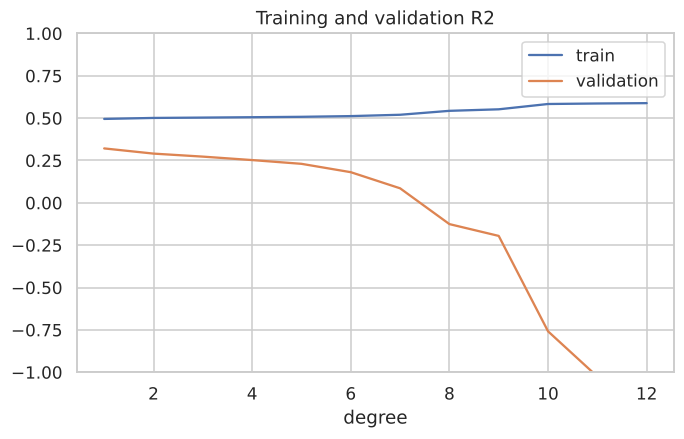

In [4]:
sample = bikes.sample(60, random_state=0)
rows = []
for d in range(1, 13):
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    r = cross_validate(m, sample[["temp_c"]], sample["rentals"], cv=5, scoring="r2", return_train_score=True)
    rows.append({"degree": d, "train": r["train_score"].mean(), "validation": r["test_score"].mean()})
pd.DataFrame(rows).set_index("degree").plot(ylim=(-1, 1), title="Training and validation R2")
plt.show()

### In-Class Exercise 4: More Data Helps

In [5]:
for n in [25, 100, 400]:
    tr = bikes.sample(n, random_state=2)
    te = bikes.drop(tr.index)
    m = make_pipeline(PolynomialFeatures(8), StandardScaler(), LinearRegression()).fit(tr[["temp_c"]], tr["rentals"])
    print(n, round(r2_score(te["rentals"], m.predict(te[["temp_c"]])), 2))

25 -13.18
100 0.45
400 0.53


## Part A: Basic

### Exercise 1: Fold Scores

In [6]:
model = make_pipeline(StandardScaler(), LogisticRegression())
s = cross_val_score(model, X, y, cv=5, scoring="recall")
print(s.round(3), round(s.mean(), 3), round(s.std(), 3))

[0.339 0.504 0.471 0.554 0.418] 0.457 0.074


### Exercise 2: Spot the Problem

In [7]:
answers = {
    (0.99, 0.62): "overfits: large gap",
    (0.55, 0.53): "underfits: both low",
    (0.86, 0.84): "fits well",
    (0.97, 0.95): "fits well: high and close",
}
for k, v in answers.items():
    print(k, v)

(0.99, 0.62) overfits: large gap
(0.55, 0.53) underfits: both low
(0.86, 0.84) fits well
(0.97, 0.95) fits well: high and close


## Part B: Intermediate

### Exercise 3: Cross-Validated Price Model

In [8]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
Xa, ya = flats[cols].astype(float), flats["price_k"]
print(round(cross_val_score(LinearRegression(), Xa, ya, cv=5, scoring="r2").mean(), 3))
print(round(-cross_val_score(LinearRegression(), Xa, ya, cv=5, scoring="neg_mean_absolute_error").mean(), 1))

0.719
11.5


### Exercise 4: Exam Model Comparison

In [9]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
for cols in [["study_hours_week"], ["study_hours_week", "attendance_pct"], ["study_hours_week", "sleep_hours", "attendance_pct"]]:
    m = make_pipeline(StandardScaler(), LogisticRegression())
    print(cols, round(cross_val_score(m, exams[cols], exams["passed"], cv=5).mean(), 3))

['study_hours_week'] 0.674
['study_hours_week', 'attendance_pct'] 0.658
['study_hours_week', 'sleep_hours', 'attendance_pct'] 0.68


## Part C: Challenge

### Exercise 5: Choosing Ridge Alpha

The test days are used only once, at the very end. Choosing alpha with the test set would be a hidden form of overfitting.

In [10]:
train = bikes.sample(25, random_state=2)
test = bikes.drop(train.index)
results = {}
for a in [0.01, 0.1, 1, 10, 100]:
    m = make_pipeline(PolynomialFeatures(12), StandardScaler(), Ridge(alpha=a))
    results[a] = cross_val_score(m, train[["temp_c"]], train["rentals"], cv=5, scoring="r2").mean()
    print(a, round(results[a], 3))
best = max(results, key=results.get)
m = make_pipeline(PolynomialFeatures(12), StandardScaler(), Ridge(alpha=best)).fit(train[["temp_c"]], train["rentals"])
print("best", best, "test R2", round(r2_score(test["rentals"], m.predict(test[["temp_c"]])), 3))

0.01 -12.055
0.1 -5.712
1 -0.859
10 0.117
100 0.015
best 10 test R2 0.413


## Part D: Cumulative Project: Apartment Prices

### Exercise 6: Apartment Prices: An Honest Score

In [11]:
from sklearn.metrics import mean_absolute_error
flats = pd.read_csv(DATA_URL + "apartments.csv")
cols = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
Xa_dev, Xa_test, ya_dev, ya_test = train_test_split(flats[cols].astype(float), flats["price_k"], test_size=0.2, random_state=7)
candidates = {
    "area only": (LinearRegression(), ["area_m2"]),
    "all features": (LinearRegression(), cols),
    "degree 2": (make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression()), cols),
}
scores = {}
for name, (m, c) in candidates.items():
    scores[name] = cross_val_score(m, Xa_dev[c], ya_dev, cv=5, scoring="r2").mean()
    print(name, round(scores[name], 3))
best = max(scores, key=scores.get)
m, c = candidates[best]
m.fit(Xa_dev[c], ya_dev)
p = m.predict(Xa_test[c])
print("chosen:", best, "test R2", round(r2_score(ya_test, p), 3), "MAE", round(mean_absolute_error(ya_test, p), 1))

area only 0.38
all features 0.723
degree 2 0.74
chosen: degree 2 test R2 0.795 MAE 9.1


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | It averages over several splits. |
| 2 | C | Once per fold. |
| 3 | B | A large gap between training and validation. |
| 4 | B | Otherwise test folds leak into the scaling. |
| 5 | C | Regularisation penalises large coefficients. |